## 1. Initial overview of the dataset

### Imports

In [9]:
import pm4py
from pm4py.objects.log.util import sorting
from collections import Counter
from pm4py.objects.log.obj import EventLog, Trace
from IPython.display import display, Markdown
from collections import defaultdict
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pm4py import discover_dfg
import seaborn as sns

### Basic Statistics

In [10]:
# Load and sort
file_path = './financial_log.xes'
log = pm4py.read_xes(file_path)
log = sorting.sort_timestamp_log(log)

# Get basic data about the file
num_cases = len(log)
num_events = sum(len(case) for case in log)
print("\nFile contains of:")
print(f"Cases: {num_cases}")
print(f"Events: {num_events}")

# Get number of unique case course
variants = pm4py.get_variants_as_tuples(log)
num_variants = len(variants)
print(f"\nNumber of process variants: {num_variants}")

parsing log, completed traces :: 100%|██████████| 13087/13087 [00:04<00:00, 3027.87it/s]



File contains of:
Cases: 13087
Events: 262200

Number of process variants: 4366


### List of Unique Events

In [11]:
activities = pm4py.get_event_attribute_values(log, "concept:name")
print("Types of activities: ")

for activity in sorted(activities.keys()):
    print(f"- {activity}")

Types of activities: 
- A_ACCEPTED
- A_ACTIVATED
- A_APPROVED
- A_CANCELLED
- A_DECLINED
- A_FINALIZED
- A_PARTLYSUBMITTED
- A_PREACCEPTED
- A_REGISTERED
- A_SUBMITTED
- O_ACCEPTED
- O_CANCELLED
- O_CREATED
- O_DECLINED
- O_SELECTED
- O_SENT
- O_SENT_BACK
- W_Afhandelen leads
- W_Beoordelen fraude
- W_Completeren aanvraag
- W_Nabellen incomplete dossiers
- W_Nabellen offertes
- W_Valideren aanvraag
- W_Wijzigen contractgegevens


### Example Case Structure

In [12]:
case_attributes = log[0].attributes
print("First case attributes: ")
for attr, value in case_attributes.items():
    print(f"- {attr}: {value}")

print(f"\n------------------------")
print("First case events: ")
case_id = log[0].attributes['concept:name']
print(f"Case ID: {case_id}")
print("Events in the first case:")
for i, event in enumerate(log[0]):
    event_number = i + 1
    print(f"  Event {event_number}:")
    # Convert event to dictionary for easy iteration
    event_dict = dict(event)
    for key, value in event_dict.items():
        print(f"    - {key}: {key} = {value}")
    if event_number == 3: # Print first 3 events for brevity
        print("    - ...")
        break


First case attributes: 
- REG_DATE: 2011-10-01 00:38:44.546000+00:00
- concept:name: 173688
- AMOUNT_REQ: 20000

------------------------
First case events: 
Case ID: 173688
Events in the first case:
  Event 1:
    - org:resource: org:resource = 112
    - lifecycle:transition: lifecycle:transition = COMPLETE
    - concept:name: concept:name = A_SUBMITTED
    - time:timestamp: time:timestamp = 2011-10-01 00:38:44.546000+00:00
  Event 2:
    - org:resource: org:resource = 112
    - lifecycle:transition: lifecycle:transition = COMPLETE
    - concept:name: concept:name = A_PARTLYSUBMITTED
    - time:timestamp: time:timestamp = 2011-10-01 00:38:44.880000+00:00
  Event 3:
    - org:resource: org:resource = 112
    - lifecycle:transition: lifecycle:transition = COMPLETE
    - concept:name: concept:name = A_PREACCEPTED
    - time:timestamp: time:timestamp = 2011-10-01 00:39:37.906000+00:00
    - ...


## 2. Data Cleaning

In [13]:
# We start with the 'log' object from Cell 1
print("Before filtering:")
print(f"{len(log)} cases")
print(f"{sum(len(case) for case in log)} events")

Before filtering:
13087 cases
262200 events


### 2.1 - Filter out cases without DECLINED/CANCELLED/APPROVED final event

In [14]:
final_event = {'A_DECLINED', 'A_CANCELLED', 'A_APPROVED'}

filtered_traces_list = [trace for trace in log if any(event['concept:name'] in final_event for event in trace)]

log_filtered_outcome = EventLog(filtered_traces_list,
                                attributes=log.attributes,
                                extensions=log.extensions,
                                classifiers=log.classifiers,
                                properties=log.properties)

cases_removed = len(log) - len(log_filtered_outcome)

print("Removed cases:")
print(f"{len(log)} - {len(log_filtered_outcome)} = {cases_removed} cases removed")

Removed cases:
13087 - 12688 = 399 cases removed


### 2.2 Find redundant activities

In [15]:
# For each activity, count how often it appears first, and how many times each predecessor leads to it
preceding = defaultdict(Counter)
first_counts = Counter()

for trace in log:
    for idx, event in enumerate(trace):
        act = event['concept:name']
        if idx == 0:
            first_counts[act] += 1
        else:
            prev = trace[idx-1]['concept:name']
            preceding[act][prev] += 1

# Candidates to remove, they always have teh exact same predecessor
candidates = [
    (act, preds.most_common(1)[0][0], sum(preds.values()))
    for act, preds in preceding.items()
    if first_counts[act] == 0 and len(preds) == 1
]

redundant_activities = [act for act, _, _ in candidates]

print("Identified reduntand events:")
for act, pred, total in candidates:
    print(f"- {act} always after {pred} ({total} records)")


Identified reduntand events:
- A_PARTLYSUBMITTED always after A_SUBMITTED (13087 records)
- A_ACCEPTED always after W_Completeren aanvraag (5113 records)
- O_SENT always after O_CREATED (7030 records)


### 2.3 - Remove Redundant Events

In [24]:
cleaned_traces = []
for trace in log_filtered_outcome:
    filtered = [e for e in trace if e['concept:name'] not in redundant_activities]
    cleaned_traces.append(Trace(filtered, attributes=trace.attributes))

cleaned_log = EventLog(cleaned_traces,
                       attributes=log_filtered_outcome.attributes,
                       extensions=log_filtered_outcome.extensions,
                       classifiers=log_filtered_outcome.classifiers,
                       properties=log_filtered_outcome.properties)

# Liczymy usunięte eventy
orig_events = sum(len(t) for t in log_filtered_outcome)
new_events  = sum(len(t) for t in cleaned_log)
removed = orig_events - new_events

print(f"After removing {len(redundant_activities)} activities:")
print(f"- {len(cleaned_log)} cases")
print(f"- {new_events} events")
print(f"\n(Deleted {removed} events)")

After removing 3 activities:
- 12688 cases
- 225432 events

(Deleted 24019 events)


### 2.4 Translate log for beter clarity

In [17]:
# Activity translation dictionary (Dutch → English)
activity_translation_map = {
    "W_Afhandelen leads": "W_Handle leads",
    "W_Beoordelen fraude": "W_Assess fraud",
    "W_Completeren aanvraag": "W_Complete application",
    "W_Nabellen incomplete dossiers": "W_Call back incomplete files",
    "W_Nabellen offertes": "W_Call back offers",
    "W_Valideren aanvraag": "W_Validate application",
    "W_Wijzigen contractgegevens": "W_Modify contract details"
}

# Apply translations to all event labels in the cleaned log
for trace in cleaned_log:
    for event in trace:
        original = event["concept:name"]
        translated = activity_translation_map.get(original, original)
        event["concept:name"] = translated


## 3. Segmentation by Ending Event

To evaluate different processes in terms of effectiveness, we need to segment them based on the ending: A_APPROVED, A_DECLINED, and A_CANCELLED.

(The classification priority is: `A_APPROVED` > `A_DECLINED` > `A_CANCELLED`)

### Classify and Segment Traces


In [18]:
segmented_cases = defaultdict(list)

for trace in cleaned_log:
    activity_set = {event["concept:name"] for event in trace}
    for outcome in ["A_APPROVED", "A_DECLINED", "A_CANCELLED"]:
        if outcome in activity_set:
            segmented_cases[outcome].append(trace)
            break

# Eventlog per every segment
log_approved = EventLog(segmented_cases["A_APPROVED"], **cleaned_log.__dict__)
log_declined = EventLog(segmented_cases["A_DECLINED"], **cleaned_log.__dict__)
log_cancelled = EventLog(segmented_cases["A_CANCELLED"], **cleaned_log.__dict__)


### Segmentation Statistics

We print the statistics for each new log

In [19]:
outcome_segments = {
    "A_APPROVED": log_approved,
    "A_DECLINED": log_declined,
    "A_CANCELLED": log_cancelled
}

for outcome, segment in outcome_segments.items():
    num_cases = len(segment)
    num_events = sum(len(trace) for trace in segment)
    avg_events = num_events / num_cases if num_cases > 0 else 0
    print(f"\n{outcome}")
    print(f"- Cases:                {num_cases}")
    print(f"- Events:               {num_events}")

total_segmented = sum(len(segment) for segment in outcome_segments.values())



A_APPROVED
- Cases:                2246
- Events:               92108

A_DECLINED
- Cases:                7635
- Events:               60921

A_CANCELLED
- Cases:                2807
- Events:               72403


## 4. Comparative Performance Analysis (KPIs)

After segmentation of data we can evaluate the Processes based on their metrics

### KPI evaluation fuction, takes into consideration:
- Average case duration in days.
- Average requested loan amount.
- Average number of work items (activities starting with 'W_').
- Total rework activities.

In [20]:
def calculate_kpis(log_segment, segment_name):
    """Compute main KPIs for a specific outcome segment."""
    durations = []
    loan_amounts = []
    work_item_counts = []
    event_counts = []

    for trace in log_segment:
        # Duration in days
        timestamps = [event["time:timestamp"] for event in trace]
        duration_days = (max(timestamps) - min(timestamps)).total_seconds() / (24 * 3600)
        durations.append(duration_days)

        # Loan amount
        loan_amounts.append(float(trace.attributes.get("AMOUNT_REQ", 0)))

        # Manual work item count
        work_items = sum(1 for event in trace if event["concept:name"].startswith("W_"))
        work_item_counts.append(work_items)

        # Total number of events in trace
        event_counts.append(len(trace))

    return {
        "Segment": segment_name,
        "Number of Cases": len(log_segment),
        "Avg. Duration (Days)": np.mean(durations),
        "Avg. Loan Amount (€)": np.mean(loan_amounts),
        "Rework Intensity (W_ per Case)": np.mean(work_item_counts),
        "Avg. Number of Events per Case": np.mean(event_counts)
    }


### Calculate KPIs

In [21]:
# Compute KPIs for all three outcome segments
kpis = [
    calculate_kpis(log_approved, "Approved"),
    calculate_kpis(log_declined, "Declined"),
    calculate_kpis(log_cancelled, "Cancelled")
]

# Display KPI table
df_kpis = pd.DataFrame(kpis)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

styled_kpi = (
    df_kpis.round(2)
    .style
    .set_caption("Key Performance Indicators by Outcome Segment")
    .format(precision=2)
)

display(styled_kpi)

,Segment,Number of Cases,Avg. Duration (Days),Avg. Loan Amount (€),Rework Intensity (W_ per Case),Avg. Number of Events per Case
0,Approved,2246,16.73,15712.53,29.49,41.01
1,Declined,7635,2.05,12191.03,5.11,7.98
2,Cancelled,2807,18.60,15162.78,19.82,25.79


### Create plots for better KPI visualisation

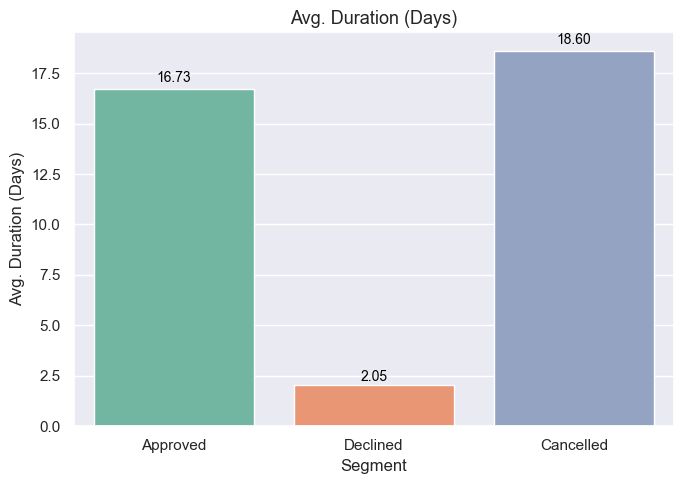

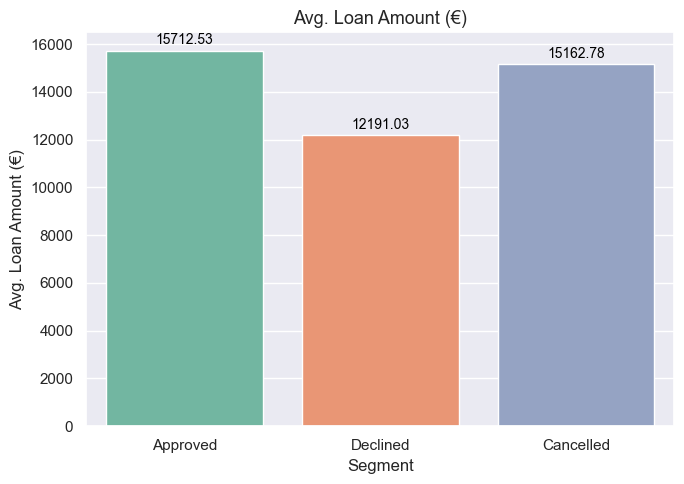

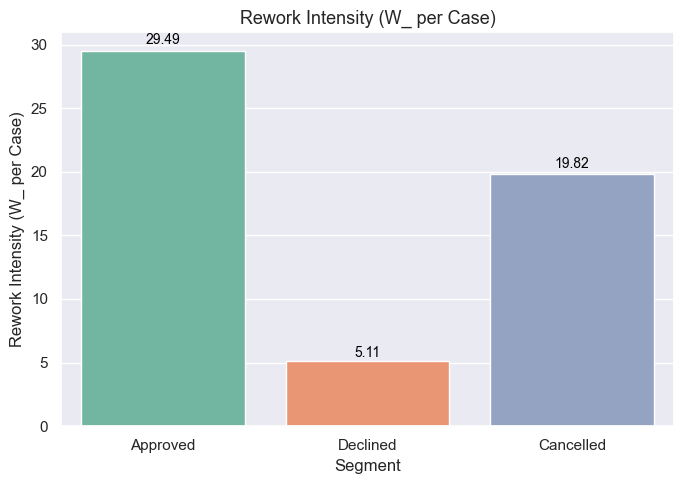

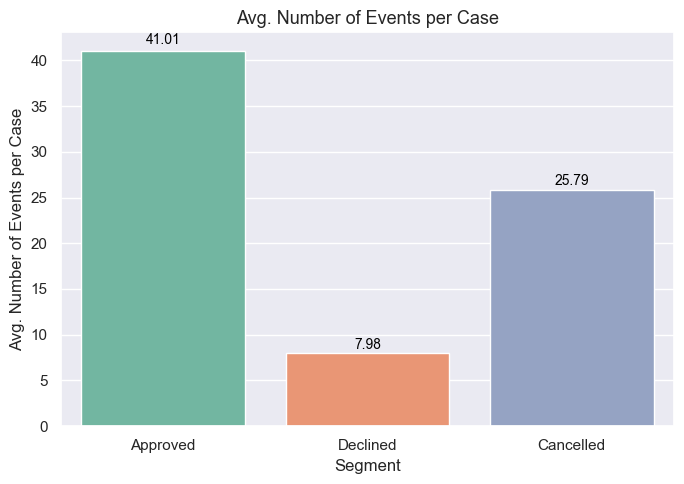

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set seaborn style
sns.set(style="darkgrid")

# Define KPI columns to plot
metrics = [
    "Avg. Duration (Days)",
    "Avg. Loan Amount (€)",
    "Rework Intensity (W_ per Case)",
    "Avg. Number of Events per Case"
]

# Create bar plot for each metric
for metric in metrics:
    plt.figure(figsize=(7, 5))

    ax = sns.barplot(
        x="Segment",
        y=metric,
        hue="Segment",
        data=df_kpis,
        palette="Set2",
        legend=False
    )

    # Add value labels on top of bars
    for idx, row in df_kpis.iterrows():
        value = row[metric]
        ax.text(
            x=idx,
            y=value * 1.01,
            s=f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            color="black"
        )

    # Set axis titles
    plt.title(metric, fontsize=13)
    plt.xlabel("Segment")
    plt.ylabel(metric)

    plt.tight_layout()
    plt.show()


## 5. Direct-Follows Analysis

Analyse of the (DFG) for better understanding common inefficiency sources

In [23]:
logs = {
    "Approved": log_approved,
    "Declined": log_declined,
    "Cancelled": log_cancelled,
}

def analyze_direct_follows(log, top_n=10):
    # Discover DFG
    dfg, _, _ = discover_dfg(log)

    # Compute durations between each (A, B) pair
    transition_durations = defaultdict(list)
    for trace in log:
        for i in range(len(trace) - 1):
            e1, e2 = trace[i], trace[i + 1]
            src, tgt = e1["concept:name"], e2["concept:name"]
            if src != tgt:
                delta = (e2["time:timestamp"] - e1["time:timestamp"]).total_seconds() / 60  # in minutes
                transition_durations[(src, tgt)].append(delta)

    # Prepare top transitions (excluding self-loops)
    dfg_filtered = {(src, tgt): freq for (src, tgt), freq in dfg.items() if src != tgt}
    sorted_dfg = sorted(dfg_filtered.items(), key=lambda x: x[1], reverse=True)

    top_transitions = []
    for (src, tgt), freq in sorted_dfg[:top_n]:
        durations = transition_durations.get((src, tgt), [])
        avg_duration = sum(durations) / len(durations) if durations else None
        top_transitions.append((src, tgt, freq, avg_duration))

    df_top = pd.DataFrame(top_transitions, columns=["Source", "Target", "Frequency", "Avg. Time (minutes)"])

    # Self-loops separately
    self_loops = [(a1, freq) for (a1, a2), freq in dfg.items() if a1 == a2]
    sorted_loops = sorted(self_loops, key=lambda x: x[1], reverse=True)[:top_n]
    df_loops = pd.DataFrame([(a, a, freq) for a, freq in sorted_loops],
                            columns=["Activity", "→", "Frequency"])

    return df_top, df_loops

# Run analysis and display
for name, log in logs.items():
    df_top, df_loops = analyze_direct_follows(log)

    display(Markdown(f"### **{name}**"))
    display(Markdown("**Top Transitions (with Avg. Time):**"))
    display(df_top.style.format({
        "Frequency": "{:.0f}",
        "Avg. Time (minutes)": "{:.2f}"
    }).set_table_attributes("style='display:inline'"))

    display(Markdown("**Top Self-Loops:**"))
    display(df_loops.style.format(precision=0).set_table_attributes("style='display:inline'"))

    print("\n\n")


### **Approved**

**Top Transitions (with Avg. Time):**

,Source,Target,Frequency,Avg. Time (minutes)
0,W_Validate application,W_Call back incomplete files,4529,42.46
1,W_Call back incomplete files,W_Validate application,4341,190.52
2,O_CREATED,W_Call back offers,2989,0.00
3,O_SENT_BACK,W_Validate application,2428,0.01
4,W_Validate application,W_Call back offers,2247,0.14
5,A_PREACCEPTED,W_Complete application,2246,0.01
6,W_Complete application,W_Call back offers,2246,4382.23
7,W_Call back offers,O_SENT_BACK,2246,0.76
8,W_Call back offers,W_Complete application,2245,0.03
9,W_Call back offers,W_Validate application,2245,3727.68


**Top Self-Loops:**

,Activity,→,Frequency
0,W_Call back incomplete files,W_Call back incomplete files,12216
1,W_Call back offers,W_Call back offers,11637
2,W_Complete application,W_Complete application,6982
3,W_Validate application,W_Validate application,4420
4,W_Handle leads,W_Handle leads,942
5,W_Assess fraud,W_Assess fraud,30
6,W_Modify contract details,W_Modify contract details,5


### **Declined**

... (5 outputs left out)

**Top Transitions (with Avg. Time):**

,Source,Target,Frequency,Avg. Time (minutes)
0,A_PREACCEPTED,W_Complete application,2806,0.01
1,O_CREATED,W_Call back offers,2147,0.00
2,A_SUBMITTED,A_PREACCEPTED,1955,0.68
3,W_Call back offers,W_Complete application,1644,5.20
4,W_Complete application,W_Call back offers,1644,4698.55
5,W_Complete application,A_CANCELLED,1166,572.11
6,W_Call back offers,O_CANCELLED,964,324.32
7,O_SELECTED,O_CREATED,958,0.08
8,W_Complete application,O_SELECTED,957,10.86
9,O_SELECTED,A_FINALIZED,957,0.00


**Top Self-Loops:**

,Activity,→,Frequency
0,W_Complete application,W_Complete application,20093
1,W_Call back offers,W_Call back offers,17019
2,W_Call back incomplete files,W_Call back incomplete files,2988
3,W_Handle leads,W_Handle leads,1235
4,W_Validate application,W_Validate application,304
5,W_Assess fraud,W_Assess fraud,17


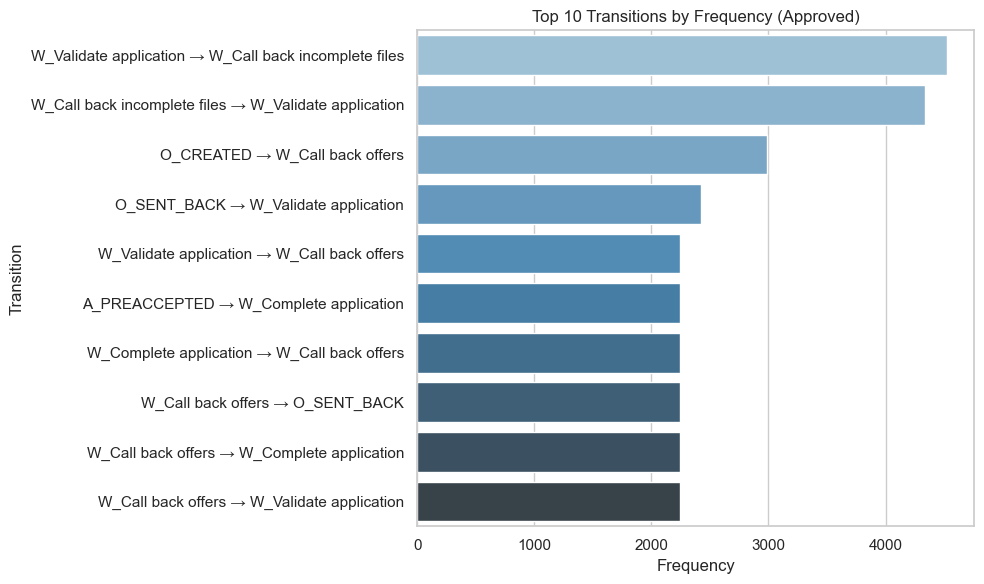

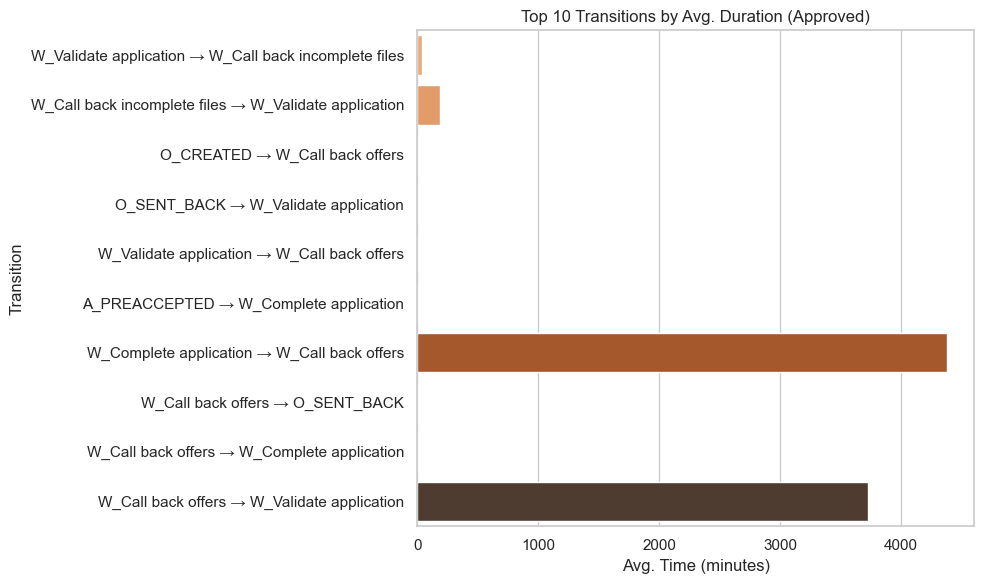

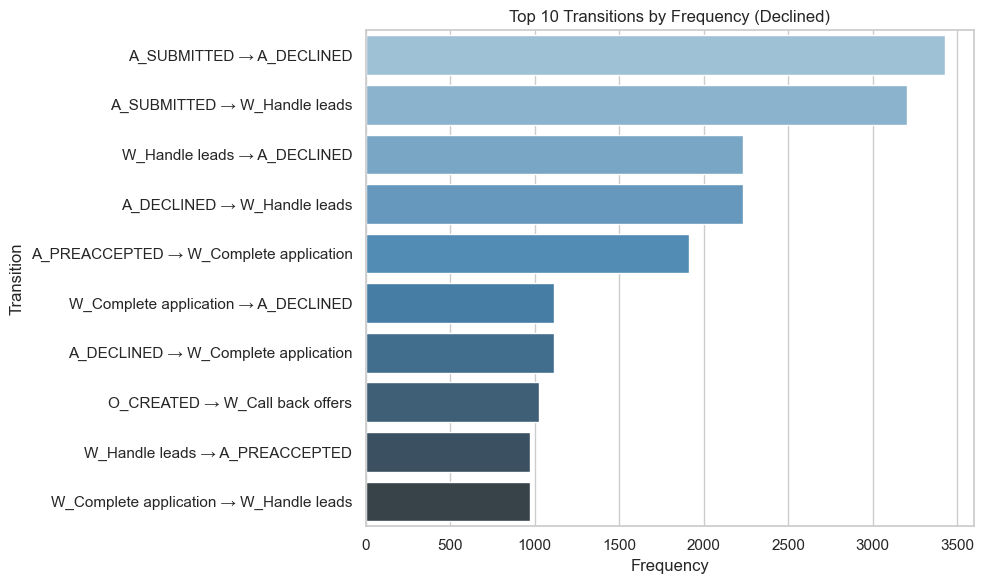

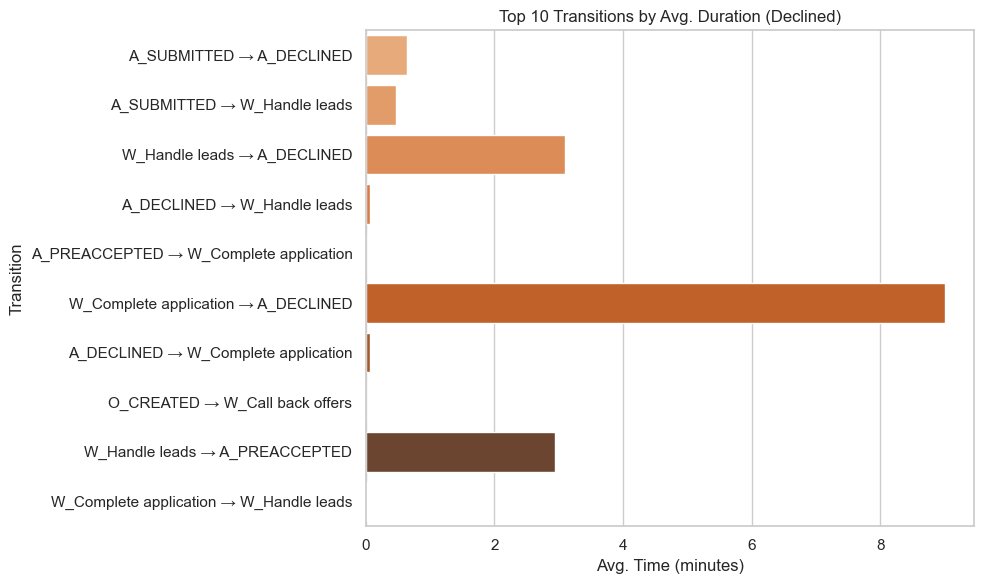

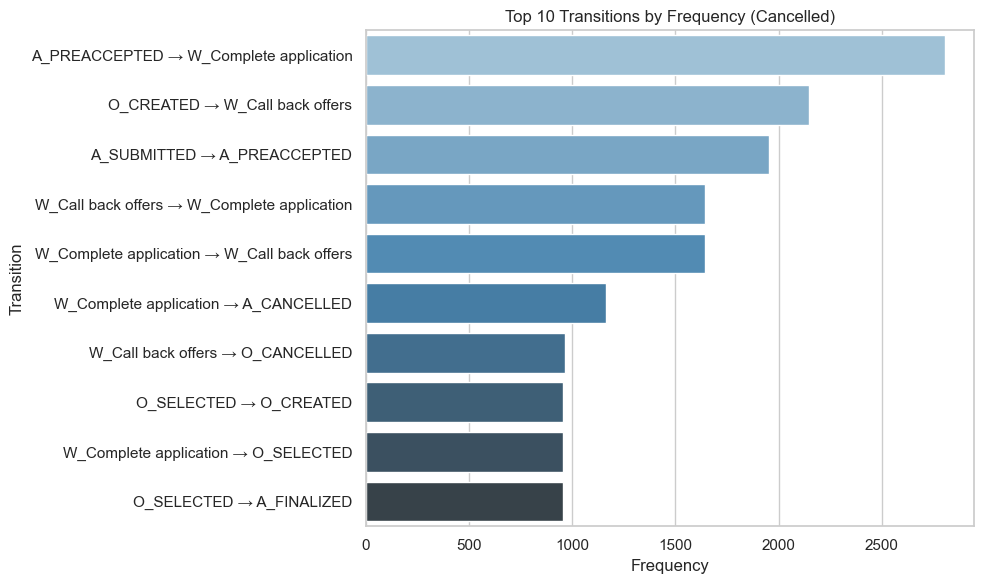

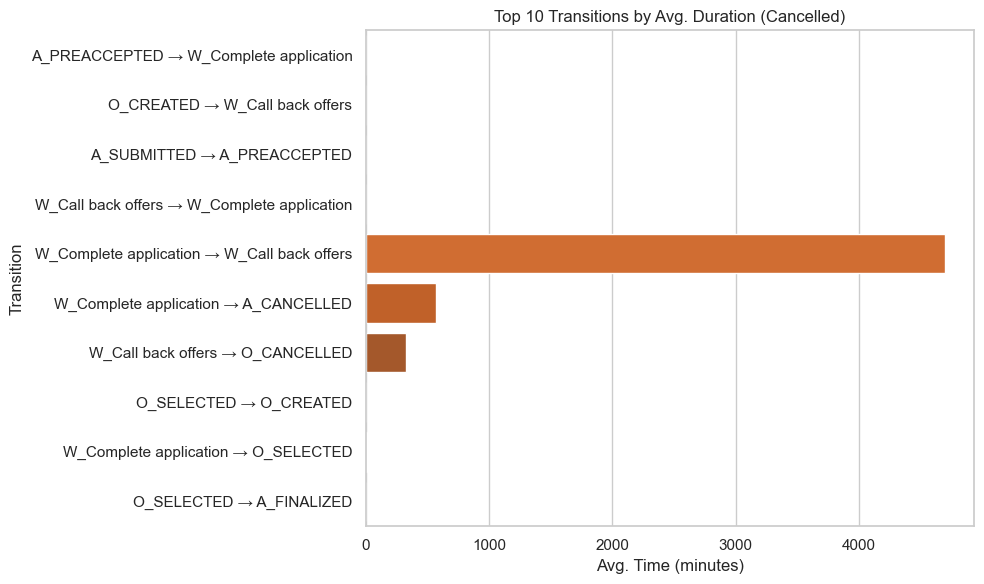

In [26]:
sns.set(style="whitegrid")

for name, log in logs.items():
    df_top, _ = analyze_direct_follows(log)

    # Add a new column to use as label
    df_top["Transition"] = df_top.apply(lambda row: f"{row['Source']} → {row['Target']}", axis=1)

    # Plot 1: Frequency of Transitions
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=df_top,
        x="Frequency",
        y="Transition",
        hue="Transition",     # to satisfy future seaborn behavior
        palette="Blues_d",
        legend=False
    )
    plt.title(f"Top {len(df_top)} Transitions by Frequency ({name})")
    plt.xlabel("Frequency")
    plt.ylabel("Transition")
    plt.tight_layout()
    plt.show()

    # Plot 2: Average Duration of Transitions
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=df_top,
        x="Avg. Time (minutes)",
        y="Transition",
        hue="Transition",     # again to avoid warning
        palette="Oranges_d",
        legend=False
    )
    plt.title(f"Top {len(df_top)} Transitions by Avg. Duration ({name})")
    plt.xlabel("Avg. Time (minutes)")
    plt.ylabel("Transition")
    plt.tight_layout()
    plt.show()
